# 01 Explore: Eskom tariffs versus inflation

Run each cell, then answer the questions in the markdown cells in your own words.

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parents[0]       # repo root, one level above notebooks/
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src import analysis
from src.load import align, check_complete, load_inputs, load_settings

settings = load_settings()
MODE = os.environ.get("DATA_MODE")           # None = real data; "synthetic" = fake demo
tariff, cpi = load_inputs(settings, MODE)
merged = align(tariff, cpi, settings["cpi_alignment"])
data = check_complete(merged, settings["base_financial_year"],
                      settings["last_financial_year"])
table = analysis.build_table(data)
table.round(2)

,fy_start_year,increase_pct,cpi_avg_pct,fy_label,gap_pp,tariff_above_cpi,tariff_index,cpi_index,real_tariff_index
0,2008,27.50,11.5,2008/09,16.00,True,127.50,111.50,114.35
1,2009,31.30,7.1,2009/10,24.20,True,167.41,119.42,140.19
2,2010,24.80,4.3,2010/11,20.50,True,208.92,124.55,167.74
3,2011,25.80,5.0,2011/12,20.80,True,262.83,130.78,200.97
4,2012,16.00,5.6,2012/13,10.40,True,304.88,138.10,220.76
5,2013,8.00,5.7,2013/14,2.30,True,329.27,145.97,225.57
6,2014,8.00,6.1,2014/15,1.90,True,355.61,154.88,229.61
7,2015,12.69,4.6,2015/16,8.09,True,400.74,162.00,247.36
8,2016,9.40,6.4,2016/17,3.00,True,438.41,172.37,254.34
9,2017,2.20,5.3,2017/18,-3.10,False,448.05,181.51,246.85


**Question 1.** In how many years was the tariff increase above CPI? Is that what you expected?

In [2]:
summary = analysis.summarise(table)
summary.round(2).T

,0
years,18.00
years_tariff_above_cpi,17.00
tariff_total_growth_pct,953.92
cpi_total_growth_pct,160.72
tariff_cagr_pct,13.98
cpi_cagr_pct,5.47
real_tariff_index_end,404.24


The Eskom tariff increase was above CPI in 17 of the 18 years from FY2008/09 to FY2025/26. The only exception was 2017/18, when the tariff rose 2.2% while CPI rose 5.3%, a gap of -3.1 percentage points. The next year, 2018/19, was only just above CPI (5.23% against 4.7%, +0.5 points). Across all 18 years the average yearly gap was about 8.8 percentage points.

This matches other analysis. A Stats SA article on Eskom’s municipal tariffs found that with the exception of 2017/18, electricity tariff increases exceeded inflation, although that covers a slightly different series and period.

**Question 2.** Compare the compound annual growth of the tariff and CPI. Why is compound growth better than averaging the yearly percentages?

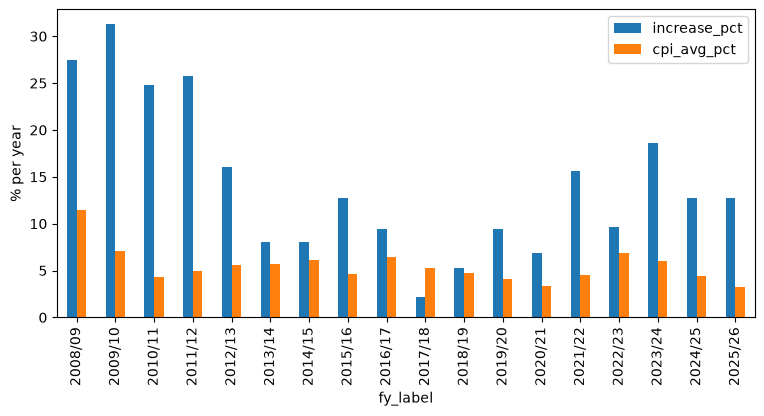

In [3]:
table.plot(x="fy_label", y=["increase_pct", "cpi_avg_pct"], kind="bar", figsize=(9, 4))
plt.ylabel("% per year")
plt.show()

The tariff grew by about 13.98% a year on a compound basis, against 5.47% a year for CPI, so the tariff grew about 2.6 times as fast each year (13.98 / 5.47).

Compound growth is better than averaging because each year’s increase applies to a price that has already risen. The compound annual rate is the single constant yearly rate that gives the same end result.

The simple average of the yearly tariff increases is 14.26%. If you grew a tariff at 14.26% for 18 years you would get roughly 11 times the starting price. The actual result is about 10.5 times (index 1,053.9), so averaging overstates growth.
For CPI the two methods almost match (5.48% against 5.47%), because CPI moved less from year to year. The gap between the two methods grows when yearly rates swing widely.
The guide’s extreme example shows the same thing: growth of 100% then 0% averages 50%, but the compound rate is 41.4%.
Question 3: The biggest gaps



**Question 3.** Which years have the biggest gap between tariff and CPI? What was happening in those years?

In [4]:
table.sort_values("gap_pp", ascending=False)[["fy_label", "gap_pp"]].head(5)

,fy_label,gap_pp
1,2009/10,24.20
3,2011/12,20.80
2,2010/11,20.50
0,2008/09,16.00
15,2023/24,12.65


The five largest gaps between tariff and CPI were:

Year	Tariff	CPI	Gap (percentage points)
2009/10	31.3%	7.1%	+24.2
2011/12	25.8%	5.0%	+20.8
2010/11	24.8%	4.3%	+20.5
2008/09	27.5%	11.5%	+16.0
2023/24	18.65%	6.0%	+12.65

Four of the five fall in the first four years of the period. A gap can be large because the tariff increase was large, because CPI was low, or both. In 2010 to 2011 CPI was only 4.3% to 5.0%, which widened the gap.

Context you can use, with sources:

Eskom had asked for about 35% a year for three years but received 24.8%, 25.8% and 25.9%, with the 25.9% later revised to 16%. So even the approved increases were well below what Eskom asked for. 
pressreader
In 2021/22 the 15.63% increase followed Eskom’s court success against NERSA in early 2021, which explains a gap of +11.1 points that year. 
poweroptimal

**Question 4.** The real tariff index divides the tariff index by the CPI index. What does a value above 100 mean?

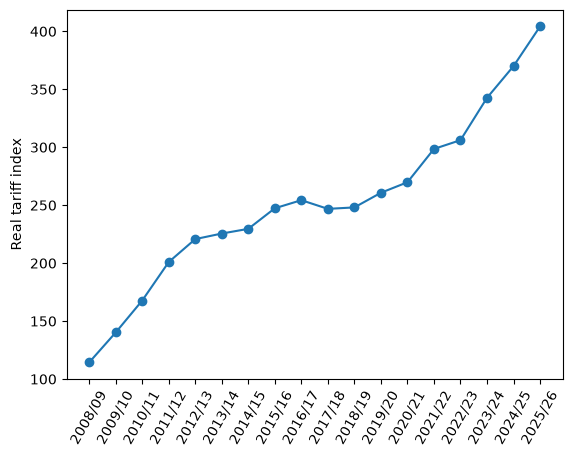

In [5]:
plt.plot(table["fy_label"], table["real_tariff_index"], marker="o")
plt.xticks(rotation=60)
plt.ylabel("Real tariff index")
plt.show()

The real tariff index divides the tariff index by the CPI index and multiplies by 100. A value above 100 means the tariff has risen faster than general prices. The final value of 404 means that by FY2025/26 the tariff is about four times higher in real terms than if it had only kept pace with inflation.

Number check: tariff index 1,053.9 / CPI index 260.7 x 100 = 404.2.

The index rises steadily over time: 114.3 in 2008/09, 254.3 by 2016/17, and 404.2 by 2025/26. It would only stay flat if tariff increases matched CPI each year, and it fell only in 2017/18.

One limit 

This is a descriptive comparison. It shows that tariffs rose faster than inflation, but it does not show why, or whether the increases were justified or cost-reflective. That is the question for Project B.

the series covers direct-customer increases, not municipal ones
some years (2014, 2017, 2020, 2021) are still being confirmed against NERSA documents